In [21]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [22]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [23]:
# 데이터 전처리 완료
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)
train_data 


array([43.5, 27.5, 42. , 21. , 18. , 24. , 27.5, 37. , 24. , 24.6, 18.7,
       16.2, 15. , 39. , 25.6, 26.5, 22. , 21.3, 27.5, 28. , 22.5, 36. ,
       34.5, 22.5, 21. , 39. , 25. , 22. , 28.7, 35. , 40. , 30. , 13.7,
       22. , 20. , 22. , 22. , 37. , 40. , 44. , 22.7, 36.5])

In [24]:
train_data = train_data.reshape(-1,1) # 2차원 배열로 변경해야함. 이유 : 길이, 무게, 두께 등등의 컬럼이 추가되기에 2차원 데이터로 변경을 위해서.
# train_data

test_data = test_data.reshape(-1,1)
test_data


array([[23. ],
       [19.6],
       [17.4],
       [32.8],
       [ 8.4],
       [21. ],
       [19. ],
       [23.5],
       [43. ],
       [27.3],
       [40. ],
       [40. ],
       [39. ],
       [43. ]])

In [25]:
# 데이터 학습
knr = KNeighborsRegressor()
knr.fit(train_data,train_label)

# 데이터 예측
predict = knr.predict(test_data)
print('예측무게 :', predict)

# 정확도 및 오차 
score = knr.score(train_data,train_label)
score2 = knr.score(test_data,test_label)
print('정확도1 :', score)
print('정확도2 :', score2)

예측무게 : [136.   99.6  70.9 620.2  60.3 121.   99.6 159.  970.  248.6 864.  864.
 784.  970. ]
정확도1 : 0.9778925261932369
정확도2 : 0.9679382245112614


In [26]:
# 오차 범위
mae = mean_absolute_error(test_label, predict)
print("오차범위(g) :" , mae)

오차범위(g) : 53.50714285714286


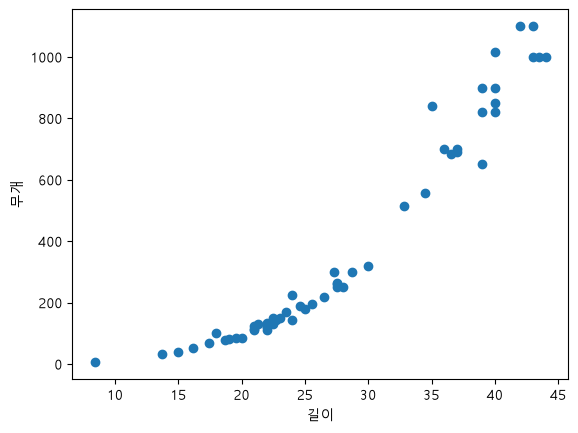

In [27]:
# 산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.xlabel('길이')
plt.ylabel('무개')
plt.show()

In [50]:
# 길이를 입력받아 무게를 예측하시오.
# 길이를 입력하세요. (예:27) 

i_data = input('생선의 길이를 입력하시오. (예: 28)')
i_data

# 입력형태 float 2차원배열[[]]
i_data = float(i_data) # 입력 형태 float
predict = knr.predict([[i_data]]) # 2차원 배열 [[]]
print('예측무게 :', predict)


예측무게 : [970.]


In [51]:
# distances, indexes = knr.kneighbors([[33]])
distances, indexes = knr.kneighbors([[i_data]])
indexes 

array([[39,  0,  2, 30, 38]])

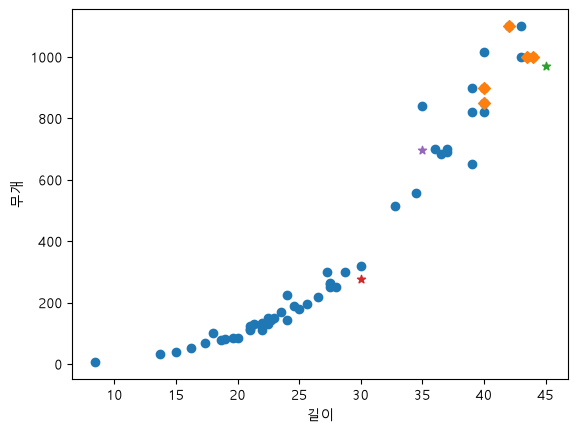

In [52]:
plt.scatter(perch_length,perch_weight)
plt.scatter(train_data[indexes],train_label[indexes],marker='D')
plt.scatter(i_data,predict,marker='*')
plt.scatter(30,276,marker='*')
plt.scatter(35,696.2,marker='*')
plt.xlabel('길이')
plt.ylabel('무개')
plt.show()